# Felicia — false correction starter

Hi Felicia! This is your starting point, not a finished model. We load the handover tables, check labels, and measure what happens when we change nothing. Your model choice and training are still yours to do.

**Labels are PROVISIONAL pending group manual review.** Please review a few examples with the group before treating the targets as ground truth. This notebook does not fit a model and never opens test data.

### Keep the boundary clear
- `X` contains only prediction-derived allowlisted features. Reference matches, labels, IDs and split metadata are not model inputs.
- Note features: `start, end, pitch, amplitude, duration, prev_gap, next_gap`; pair features: `gap, pitch_delta, duration_sum`.
- Missing/ambiguous labels are excluded only from this task's training-label diagnostics, never from full end-to-end evaluation.
- Timing targets are absolute seconds; pitch targets are absolute MIDI. Positive classifier labels mean merge the pair / remove the false note.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

# Open from this notebook folder, or run from the project root.
HERE = next(p / 'notebooks' / 'correction_handover' for p in [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'GTSinger_100_unique_sample'] if (p / 'selected_100.csv').exists())
sys.path.insert(0, str(HERE))
import correction_utils as cu
DATA = HERE / '..' / '..' / 'basic_pitch_runs' / 'correction_handover'
notes = pd.read_csv(DATA / 'train_features.csv', dtype={'note_id':str,'recording_id':str,'sample_id':str})
note_targets = pd.read_csv(DATA / 'proposed_v2' / 'train_targets_v2.csv', dtype={'note_id':str}).rename(columns={'false_note':'false_label','reference_start':'target_start','reference_end':'target_end','reference_pitch':'target_pitch'})
assert notes['split'].eq('train').all(), 'Only train data belongs in this starter.'
manifest = pd.read_csv(DATA / 'training_recording_manifest.csv')
cu.validate_notes(notes, manifest)
features, targets = notes, note_targets
TASK = 'false'
X, joined = cu.training_data(features, targets, TASK)
print('Feature allowlist:', X.columns.tolist())
print('Rows:', len(X), '| target-row coverage: 100%')
display(X.head())


Feature allowlist: ['start', 'end', 'pitch', 'amplitude', 'duration', 'prev_gap', 'next_gap']
Rows: 7623 | target-row coverage: 100%


,start,end,pitch,amplitude,duration,prev_gap,next_gap
0,0.394739,0.684989,55.0,0.729802,0.290249,0.00000,0.092880
1,0.777868,0.986848,49.0,0.616202,0.208980,0.09288,0.034830
2,1.021678,1.265488,54.0,0.627965,0.243810,0.03483,0.150930
3,1.416417,1.625397,49.0,0.576493,0.208980,0.15093,0.092880
4,1.718277,1.915646,55.0,0.518624,0.197370,0.09288,0.082554


## Check what we can actually learn from

Target rows must cover every feature ID, even when their task labels are missing. For classification, inspect both class counts before choosing a method. For timing/pitch, the value counts below describe target coverage rather than classifier classes.

In [2]:
label_columns = cu.TARGETS[TASK]
usable = joined[label_columns].notna().all(axis=1)
if 'ambiguous' in joined:
    # CSV accepts True/False or 1/0. Reject unknown encodings rather than guessing.
    ambiguity = joined['ambiguous'].astype(str).str.lower().map({'true':True,'false':False,'1':True,'0':False})
    assert ambiguity.notna().all(), 'ambiguous must be explicit True/False or 1/0'
    usable &= ~ambiguity
print({'total_rows':len(joined), 'usable_task_labels':int(usable.sum()),
       'excluded_task_labels':int((~usable).sum())})
for column in label_columns:
    print(column, 'non-null coverage:', float(joined[column].notna().mean()))
    display(joined.loc[usable,column].value_counts(dropna=False).rename('count'))
labelled = joined.loc[usable].copy()
X_task = X.loc[usable].copy()  # Only these allowlisted columns may reach your future model.
folds = pd.read_csv(DATA / 'folds.csv').set_index('sample_id')['fold']
groups = labelled['sample_id'].copy()
fold_ids = groups.map(folds)
assert fold_ids.notna().all(), 'Missing training-song fold'
print('Labelled examples per song-grouped fold:', fold_ids.value_counts().sort_index().to_dict())
print('Do not fit until the group approves the provisional label version.')


{'total_rows': 7623, 'usable_task_labels': 3893, 'excluded_task_labels': 3730}
false_label non-null coverage: 0.510691328873147


false_label
0.0    3697
1.0     196
Name: count, dtype: int64

Labelled examples per song-grouped fold: {0: 681, 1: 922, 2: 873, 3: 692, 4: 725}
Do not fit until the group approves the provisional label version.


## Our first comparison: do nothing

This is a real no-change baseline on usable training task labels, not evidence of validation performance. Empty-label metrics have no useful interpretation. Nothing is fitted here.

In [3]:
if len(labelled) == 0:
    baseline = {'status':'BLOCKED_NO_REVIEWED_OR_PROVISIONAL_TARGETS', 'n':0, 'metrics':None}
else:
    baseline = cu.classification_metrics(labelled[label_columns[0]], np.zeros(len(labelled), dtype=int))
print('No-change task baseline (not a trained model):', baseline)


No-change task baseline (not a trained model): {'n': 3893, 'tp': 0, 'fp': 0, 'fn': 196, 'tn': 3697, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'accuracy': 0.9496532237349088}


## Felicia: extra-note correction models (exploratory)

**Task:** tuned BP + decision tree / random forest + PM2S; tuned BP + logistic regression / Gaussian naive Bayes + PM2S; evaluation and results; best model and what was done to improve it.

**Status: EXPLORATORY.** The introduction above says "This notebook does not fit a model"; that describes the original starter. This section fits models on the **proposed v2 labels**, which are automatic and **not approved**. The README's rule still applies: final training follows shared label review. Training songs only, with the fixed song folds; validation is used once at the end (section 8); test is never opened.

### 1. Setup

Label counts per fold (fold 0 has only 3 delete notes), and the unchanged-BP score that every result is compared with. Scores always come from the shared evaluator `cu.evaluate_end_to_end`, on **all** notes and **all** reference notes.

In [4]:
# EXPLORATORY: v2 labels are automatic, not manually verified and not approved (group_review_gate.json).
LABEL_VERSION = 'proposed_v2/train_targets_v2.csv (unapproved, exploratory)'
SEED = 42
TARGET_PRECISION = 0.90  # delete only above the lowest cutoff that reaches this precision on training folds

y = labelled[label_columns[0]].astype(int)  # 1 = delete, 0 = retain; unknown notes are not in y
note_fold = notes['sample_id'].map(folds)    # fold of EVERY note, labelled or not
assert note_fold.notna().all()

fold_table = pd.crosstab(fold_ids, y).rename(columns={0: 'retain', 1: 'delete'})
fold_table['unknown'] = note_fold[~usable].value_counts().reindex(fold_table.index, fill_value=0)
display(fold_table)

# Evaluator-only tables (never model inputs): all reference notes and all recordings, including empty ones.
eval_references = pd.read_csv(DATA / 'references_train.csv', dtype={'note_id': str, 'recording_id': str})
eval_manifest = pd.read_csv(DATA / 'training_recording_manifest.csv', dtype={'recording_id': str, 'sample_id': str})

def score(table, references=None, manifest=None):
    """Shared evaluator: song-macro onset+pitch F1 and offset-aware F1, plus per-song onset+pitch F1."""
    result = cu.evaluate_end_to_end(table, eval_references if references is None else references,
                                    eval_manifest if manifest is None else manifest)
    return result['summary'], pd.DataFrame(result['songs']).set_index('sample_id')['f1']

bp_unchanged = notes[cu.NOTE_COLUMNS].copy()
BP_SUMMARY, BP_SONG_F1 = score(bp_unchanged)
print('Unchanged BP, 60 training songs: onset+pitch F1 %.4f, offset-aware F1 %.4f'
      % (BP_SUMMARY['song_macro_f1'], BP_SUMMARY['song_macro_offset_f1']))

false_label,retain,delete,unknown
sample_id,,,
0,678,3,535
1,856,66,964
2,827,46,867
3,671,21,715
4,665,60,649


Unchanged BP, 60 training songs: onset+pitch F1 0.2628, offset-aware F1 0.1539


### 2. Features

- **Set A**: the 7 starter features (`cu.NOTE_FEATURES`), the starter allowlist. **This set fits the README and starter best.**
- **Set A+B**: A plus 10 context features computed from the predicted notes only, such as position in the clip, pitch jumps to neighbours, distance from the recording's usual pitch, and relative loudness. B is outside the allowlist (it also uses `audio_duration`), so it is an extension that needs group approval.

In [5]:
def add_context_features(frame, window=1.0):
    """Context computed from the predicted notes only (never reference or target columns)."""
    f = frame.sort_values(['recording_id', 'start', 'end', 'pitch']).copy()
    g = f.groupby('recording_id', sort=False)
    f['is_first'] = (g.cumcount() == 0).astype(float)  # separates a boundary from a true zero gap
    f['is_last'] = (g.cumcount(ascending=False) == 0).astype(float)
    f['position'] = f['start'] / f['audio_duration']
    f['time_to_clip_end'] = f['audio_duration'] - f['end']
    f['pitch_jump_prev'] = (f['pitch'] - g['pitch'].shift(1)).abs().fillna(0.)
    f['pitch_jump_next'] = (f['pitch'] - g['pitch'].shift(-1)).abs().fillna(0.)
    f['pitch_from_median'] = (f['pitch'] - g['pitch'].transform('median')).abs()
    f['amp_rel'] = f['amplitude'] / g['amplitude'].transform('median')
    f['notes_in_recording'] = g['pitch'].transform('size').astype(float)
    f['local_density'] = g['start'].transform(lambda s: np.searchsorted(s.to_numpy(), s + window, 'right')
                                              - np.searchsorted(s.to_numpy(), s - window, 'left') - 1).astype(float)
    return f.loc[frame.index]

FEATURES_A = list(cu.NOTE_FEATURES)
FEATURES_B = ['is_first', 'is_last', 'position', 'time_to_clip_end', 'pitch_jump_prev', 'pitch_jump_next',
              'pitch_from_median', 'amp_rel', 'notes_in_recording', 'local_density']
FEATURE_SETS = {'A': FEATURES_A, 'A+B': FEATURES_A + FEATURES_B}

X_all = add_context_features(notes)[FEATURES_A + FEATURES_B].astype(float)  # one row per note, same index as notes
assert X_all.index.equals(notes.index) and np.isfinite(X_all.to_numpy()).all()
assert np.allclose(X_all.loc[usable, FEATURES_A], X_task), 'Set A must equal the starter allowlist'
display(X_all.loc[usable].groupby(y.to_numpy()).median().T.rename(columns={0: 'retain median', 1: 'delete median'}))

,retain median,delete median
start,4.379529,8.317879
end,4.855538,8.712619
pitch,62.000000,66.000000
amplitude,0.688116,0.634185
duration,0.336689,0.243810
prev_gap,0.128994,0.139320
next_gap,0.139320,0.063855
is_first,0.000000,0.000000
is_last,0.000000,0.000000
position,0.417109,0.604177


### 3. Models and training

| Model | Settings tried (chosen on training folds) |
|---|---|
| Decision tree | depth 3 / 5 / 8 / unlimited · min leaf 5 / 20 / 50 · class weight none / balanced |
| Random forest (300 trees) | depth unlimited / 10 · min leaf 1 / 5 / 20 · class weight none / balanced |
| Logistic regression (standardised) | C 0.01 / 0.1 / 1 / 10 · class weight none / balanced |
| Gaussian naive Bayes | raw or Yeo-Johnson-transformed inputs · smoothing 1e-9 / 1e-6 / 1e-3 |

**How a note gets deleted:** the model gives each note a probability of being extra. The note is deleted if that probability is at or above a cutoff: the lowest cutoff that reaches **0.90 precision** on the training folds. If none does, that fold deletes nothing.

**Fair testing:** for each of the 5 fixed song folds, settings and cutoff are chosen using only the other 4 folds, then every note of the held-out songs is predicted, unknowns included.

In [6]:
import warnings
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import precision_recall_curve

# (pipeline, hyperparameter grid). Scaling sits inside the pipeline, so it is fitted on training folds only.
MODELS = {
    'decision_tree': (Pipeline([('clf', DecisionTreeClassifier(random_state=SEED))]),
                      {'clf__max_depth': [3, 5, 8, None], 'clf__min_samples_leaf': [5, 20, 50],
                       'clf__class_weight': [None, 'balanced']}),
    'random_forest': (Pipeline([('clf', RandomForestClassifier(n_estimators=300, max_features='sqrt', random_state=SEED))]),
                      {'clf__max_depth': [None, 10], 'clf__min_samples_leaf': [1, 5, 20],
                       'clf__class_weight': [None, 'balanced_subsample']}),
    'logistic_regression': (Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=5000))]),
                            {'clf__C': [0.01, 0.1, 1, 10], 'clf__class_weight': [None, 'balanced']}),
    'gaussian_nb': (Pipeline([('scale', 'passthrough'), ('clf', GaussianNB())]),
                    {'scale': ['passthrough', PowerTransformer()], 'clf__var_smoothing': [1e-9, 1e-6, 1e-3]}),
}

def pick_cutoff(y_true, prob):
    """Lowest cutoff whose precision reaches TARGET_PRECISION; inf = delete nothing."""
    precision, _, cutoffs = precision_recall_curve(y_true, prob)
    ok = precision[:-1] >= TARGET_PRECISION
    return float(cutoffs[ok].min()) if ok.any() else np.inf

def run_cv(model_name, feature_set, labels=None, scoring='f1'):
    """For each held-out fold: choose hyperparameters and the cutoff on the other four folds only (one fold
    held out at a time, so songs stay together), then predict EVERY note of the held-out songs."""
    y_lab = y if labels is None else labels
    pipe, grid = MODELS[model_name]
    cols = FEATURE_SETS[feature_set]
    X_lab, f_lab = X_all.loc[y_lab.index, cols], note_fold[y_lab.index]
    prob = pd.Series(np.nan, index=notes.index)
    cutoff = pd.Series(np.inf, index=notes.index)
    for k in sorted(folds.unique()):
        tr, held = f_lab.ne(k), note_fold.eq(k)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', category=UserWarning)
            search = GridSearchCV(pipe, grid, scoring=scoring, cv=LeaveOneGroupOut(), n_jobs=-1)
            search.fit(X_lab[tr], y_lab[tr], groups=f_lab[tr])
            inner = cross_val_predict(search.best_estimator_, X_lab[tr], y_lab[tr], groups=f_lab[tr],
                                      cv=LeaveOneGroupOut(), method='predict_proba', n_jobs=-1)[:, 1]
        cutoff[held] = pick_cutoff(y_lab[tr], inner)
        prob[held] = search.predict_proba(X_all.loc[held, cols])[:, 1]
    return dict(prob=prob, delete=prob.ge(cutoff), cutoffs=cutoff.groupby(note_fold).first())

RESULTS = {(m, fs): run_cv(m, fs) for m in MODELS for fs in FEATURE_SETS}
print('Trained', len(RESULTS), 'configurations (4 models x 2 feature sets, 5 held-out folds each).')

Trained 8 configurations (4 models x 2 feature sets, 5 held-out folds each).


### 4. Evaluation & results

- `precision`, `recall`, `task_f1`: deleting the 196 labelled extra notes vs keeping the 3,697 labelled real notes (task metrics).
- `onset_pitch_f1` (README's main metric) and `offset_f1`: the whole corrected transcription against all reference notes, with `delta_*` compared to unchanged BP (0.2628 / 0.1539).
- `folds_improved` (of 5); `deleted` = notes removed; `deleted_bp_matched` = removed notes that BP had right (each costs F1); `cutoffs` = the cutoff used in each fold.
- Task metrics and transcription F1 are separate measures and are never averaged.

In [7]:
from librosa import midi_to_hz
from mir_eval.transcription import match_notes

def onset_matched(table, references=None):
    """True for notes the evaluator matches to a reference (50 ms onset, 50 cents). Evaluator-only."""
    refs = dict(tuple((eval_references if references is None else references).groupby('recording_id')))
    hit = pd.Series(False, index=table.index)
    for rid, n in table.groupby('recording_id'):
        if rid in refs:
            r = refs[rid]
            pairs = match_notes(r[['start', 'end']].to_numpy(float), midi_to_hz(r['pitch'].to_numpy(float)),
                                n[['start', 'end']].to_numpy(float), midi_to_hz(n['pitch'].to_numpy(float)),
                                onset_tolerance=.05, pitch_tolerance=50., offset_ratio=None, strict=False)
            hit.loc[n.index[[e for _, e in pairs]]] = True
    return hit

BP_MATCHED = onset_matched(bp_unchanged)

def evaluate(name, r):
    """Task metrics on the labelled notes + full-transcription scores on all notes, against unchanged BP."""
    task = cu.classification_metrics(y, r['delete'][y.index].astype(int))
    summary, song_f1 = score(notes.loc[~r['delete'], cu.NOTE_COLUMNS])
    fold_delta = (song_f1 - BP_SONG_F1).groupby(folds).mean()
    return dict(system=name, precision=task['precision'], recall=task['recall'], task_f1=task['f1'],
                onset_pitch_f1=summary['song_macro_f1'], delta_f1=summary['song_macro_f1'] - BP_SUMMARY['song_macro_f1'],
                offset_f1=summary['song_macro_offset_f1'],
                delta_offset_f1=summary['song_macro_offset_f1'] - BP_SUMMARY['song_macro_offset_f1'],
                folds_improved=int((fold_delta > 1e-12).sum()), deleted=int(r['delete'].sum()),
                deleted_bp_matched=int((r['delete'] & BP_MATCHED).sum()),
                cutoffs=', '.join('inf' if np.isinf(c) else f'{c:.2f}' for c in r['cutoffs']))

results = pd.DataFrame([evaluate(f'{m} ({fs})', r) for (m, fs), r in RESULTS.items()])
results = results.sort_values('onset_pitch_f1', ascending=False, kind='mergesort').reset_index(drop=True)
display(results.round(4))
def best_with(suffix):
    name = results[results['system'].str.endswith(suffix)].iloc[0]['system']
    return next(k for k in RESULTS if f'{k[0]} ({k[1]})' == name)

BEST_A_KEY, BEST_AB_KEY = best_with('(A)'), best_with('(A+B)')
print('Best with the 7 starter features (set A):', BEST_A_KEY, '| best if extra features are allowed (A+B):', BEST_AB_KEY)

,system,precision,recall,task_f1,onset_pitch_f1,delta_f1,offset_f1,delta_offset_f1,folds_improved,deleted,deleted_bp_matched,cutoffs
0,logistic_regression (A+B),0.9412,0.2449,0.3887,0.2697,0.0069,0.1581,0.0042,5,457,2,"0.58, 0.53, 0.56, 0.49, 0.54"
1,gaussian_nb (A),0.8571,0.1837,0.3025,0.2692,0.0064,0.1579,0.0041,4,431,1,"0.89, 0.94, 0.88, inf, 0.88"
2,random_forest (A+B),0.8254,0.2653,0.4015,0.2682,0.0055,0.1570,0.0031,5,401,7,"0.58, 0.53, 0.58, 0.55, 0.55"
3,random_forest (A),0.7885,0.2092,0.3306,0.2655,0.0028,0.1556,0.0017,4,253,10,"0.79, 0.50, 0.56, 0.65, 0.60"
4,decision_tree (A+B),0.9375,0.0765,0.1415,0.2637,0.0009,0.1543,0.0005,3,68,1,"0.76, inf, 1.00, inf, 1.00"
5,decision_tree (A),0.8667,0.0663,0.1232,0.2637,0.0009,0.1544,0.0006,2,42,0,"inf, inf, 0.89, inf, 1.00"
6,logistic_regression (A),0.2000,0.0051,0.0100,0.2631,0.0003,0.1541,0.0002,1,42,2,"0.97, 0.53, inf, inf, 0.97"
7,gaussian_nb (A+B),0.0000,0.0000,0.0000,0.2628,0.0000,0.1539,0.0000,0,0,0,"inf, inf, inf, inf, inf"


Best with the 7 starter features (set A): ('gaussian_nb', 'A') | best if extra features are allowed (A+B): ('logistic_regression', 'A+B')


### 5. PM2S post-processing

[PM2S](https://github.com/cheriell/PM2S) (Liu et al., ISMIR 2022) is a pretrained performance-MIDI-to-score model. It predicts beats and snaps each note's start and end to a beat grid; it keeps every note and changes **timing only** (Le Xin's task area). It is applied after each of the 8 models (to the notes each model keeps), and to unchanged BP to see its effect alone. Each row shows the score before and after PM2S. It was trained on piano, and the references follow the actual sung timing, so snapping can move notes away from them.

In [8]:
# Setup (once): pip install torch pretty_midi mido   (into the project .venv)
#               git clone https://github.com/cheriell/PM2S external/PM2S   (tested at commit 9586f91)
#               put RNNJointBeatModel.pth and RNNJointQuantisationModel.pth from https://zenodo.org/records/10520196
#               into external/PM2S/pm2s/_model_state_dicts/{beat,quantisation}/  (PM2S's own downloader needs wget)
PM2S_DIR = (HERE / '..' / '..' / 'external' / 'PM2S').resolve()
PM2S_WEIGHTS = [PM2S_DIR / 'pm2s' / '_model_state_dicts' / 'beat' / 'RNNJointBeatModel.pth',
                PM2S_DIR / 'pm2s' / '_model_state_dicts' / 'quantisation' / 'RNNJointQuantisationModel.pth']
PM2S_AVAILABLE = all(w.exists() for w in PM2S_WEIGHTS)
if PM2S_AVAILABLE:
    sys.path.insert(0, str(PM2S_DIR))
    try:
        from pm2s.features.beat import RNNJointBeatProcessor
        from pm2s.features.quantisation import RNNJointQuantisationProcessor
        PM2S_BEAT, PM2S_QUANT = RNNJointBeatProcessor(), RNNJointQuantisationProcessor()
    except ImportError:  # torch / pretty_midi / mido not installed
        PM2S_AVAILABLE = False
AUDIO_DURATION = eval_manifest.set_index('recording_id')['duration_seconds_if_validated'].astype(float)

def pm2s_quantise(table):
    """Run PM2S on these notes (per recording) and move each start/end to PM2S's quantised time.
    Recordings where PM2S finds fewer than 2 beats keep their timing."""
    out = table[cu.NOTE_COLUMNS].copy()
    for _, n in table.sort_values(['recording_id', 'start']).groupby('recording_id', sort=False):
        seq = np.c_[n['pitch'], n['start'], n['end'] - n['start'],
                    np.clip(np.round(n['amplitude'] * 127), 1, 127)].astype('float32')  # velocity from BP amplitude
        try:
            beats = np.asarray(PM2S_BEAT.process_note_seq(seq)[0], dtype=float)
            position, value = PM2S_QUANT.process_note_seq(seq)  # onset position and note value, in beats
        except IndexError:  # PM2S's beat post-processing fails when it finds only one beat
            continue
        if len(n) < 2 or len(beats) < 2:
            continue
        ibi = np.diff(beats)
        onset = n['start'].to_numpy()
        j = np.clip(np.searchsorted(beats, onset, 'right') - 1, 0, len(ibi) - 1)  # beat interval holding the onset
        anchor = beats[j] + np.floor((onset - beats[j]) / ibi[j]) * ibi[j]        # extends the grid before/after
        start = np.maximum(anchor + (position - np.floor(position)) * ibi[j], 0.)
        end = np.minimum(np.where(value > 0, start + value * ibi[j], n['end']), AUDIO_DURATION[n['recording_id'].iloc[0]])
        ok = end > start + 1e-3
        out.loc[n.index[ok], 'start'], out.loc[n.index[ok], 'end'] = start[ok], end[ok]
    return out

# PM2S after unchanged BP and after each of the 8 models (PM2S re-run on the notes each model keeps).
pm2s_rows = []
systems = [('BP unchanged', notes)] + [(f'{m} ({fs})', notes.loc[~r['delete']]) for (m, fs), r in RESULTS.items()]
if not PM2S_AVAILABLE:
    systems = []
    print('PM2S not installed: section skipped (see setup lines at the top). Saved results: exports/felicia_false_results_pm2s_*.csv')
for name, table in systems:
    out = pm2s_quantise(table)
    before, _ = score(table[cu.NOTE_COLUMNS])
    after, _ = score(out)
    shift = (out['start'] - table['start']).abs()
    pm2s_rows.append(dict(system=name, onset_pitch_f1=before['song_macro_f1'], onset_pitch_f1_pm2s=after['song_macro_f1'],
                          change=after['song_macro_f1'] - before['song_macro_f1'], offset_f1=before['song_macro_offset_f1'],
                          offset_f1_pm2s=after['song_macro_offset_f1'], median_onset_shift_s=shift.median(),
                          onsets_moved_over_50ms=(shift > .05).mean()))
pm2s_results = pd.DataFrame(pm2s_rows)
if len(pm2s_results):
    display(pm2s_results.round(4))

,system,onset_pitch_f1,onset_pitch_f1_pm2s,change,offset_f1,offset_f1_pm2s,median_onset_shift_s,onsets_moved_over_50ms
0,BP unchanged,0.2628,0.1290,-0.1337,0.1539,0.0307,0.3019,0.7186
1,decision_tree (A),0.2637,0.1299,-0.1338,0.1544,0.0306,0.3019,0.7167
2,decision_tree (A+B),0.2637,0.1309,-0.1328,0.1543,0.0314,0.3070,0.7185
3,random_forest (A),0.2655,0.1292,-0.1363,0.1556,0.0288,0.3153,0.7168
4,random_forest (A+B),0.2682,0.1337,-0.1345,0.1570,0.0305,0.3196,0.7137
5,logistic_regression (A),0.2631,0.1294,-0.1337,0.1541,0.0305,0.3023,0.7181
6,logistic_regression (A+B),0.2697,0.1355,-0.1342,0.1581,0.0322,0.3251,0.7089
7,gaussian_nb (A),0.2692,0.1348,-0.1343,0.1579,0.0336,0.3166,0.7090
8,gaussian_nb (A+B),0.2628,0.1290,-0.1337,0.1539,0.0307,0.3019,0.7186


### 6. Error analysis

1. What the final model (Gaussian NB A) deleted, by v2 label and by whether BP had matched the note.
2. Per-song F1 change by vocal range.
3. What the model relies on (refitted on all labelled notes).
4. Listening: `listen('<note_id>')` plots and plays any note. Blue = reference, orange = BP, red = the note.

Deletions of ('gaussian_nb', 'A')


evaluator,BP matched (deleting costs F1),BP unmatched (deleting raises precision),All
v2 label,,,
labelled delete,0,36,36
labelled retain,1,5,6
unknown,0,389,389
All,1,430,431


,songs,mean_delta_f1,songs_worse,deleted
vocal_range,,,,
Alto,15,0.0031,0,43.0
Bass,8,0.0182,1,162.0
Soprano,18,0.0025,0,28.0
Tenor,19,0.0078,0,198.0


,retain mean,delete mean
start,-0.037,0.691
end,-0.036,0.671
pitch,-0.011,0.200
amplitude,0.030,-0.567
duration,0.021,-0.397
prev_gap,0.000,-0.005
next_gap,0.001,-0.013


Deletions that cost a match: ['aa834d3602ff386ba951:n00007'] | call listen(note_id) on any note


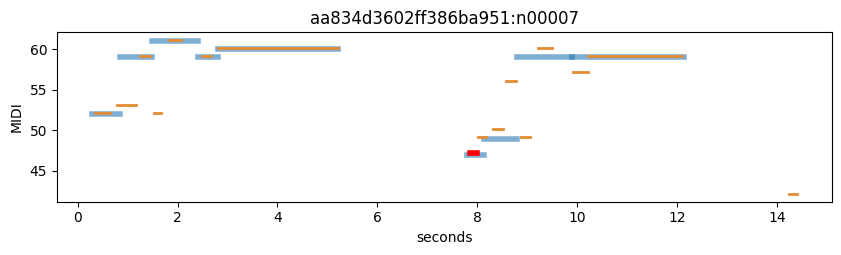

In [9]:
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio
from sklearn.tree import export_text

best = RESULTS[BEST_A_KEY]  # final model (set A)
label_name = pd.Series('unknown', index=notes.index)
label_name[y.index] = y.map({1: 'labelled delete', 0: 'labelled retain'})

# 1. What was deleted: v2 label x whether unchanged BP had matched the note to a reference
print('Deletions of', BEST_A_KEY)
display(pd.crosstab(label_name[best['delete']], BP_MATCHED[best['delete']].map(
    {True: 'BP matched (deleting costs F1)', False: 'BP unmatched (deleting raises precision)'}),
    rownames=['v2 label'], colnames=['evaluator'], margins=True))

# 2. Who is affected: per-song F1 change by vocal range (evaluator metadata, not a model input)
_, best_song_f1 = score(notes.loc[~best['delete'], cu.NOTE_COLUMNS])
meta = eval_manifest.groupby('sample_id')[['language', 'vocal_range']].first()
song = meta.assign(delta_f1=best_song_f1 - BP_SONG_F1, deleted=notes.loc[best['delete']].groupby('sample_id').size()).fillna({'deleted': 0})
display(song.groupby('vocal_range').agg(songs=('delta_f1', 'size'), mean_delta_f1=('delta_f1', 'mean'),
                                        songs_worse=('delta_f1', lambda d: int((d < -1e-12).sum())),
                                        deleted=('deleted', 'sum')).round(4))

# 3. What the model relies on: refit on all labelled notes (hyperparameters and cutoff chosen on the five folds)
def fit_final(model_name, feature_set, labels=None, scoring='f1'):
    y_lab = y if labels is None else labels
    pipe, grid = MODELS[model_name]
    cols = FEATURE_SETS[feature_set]
    X_lab, f_lab = X_all.loc[y_lab.index, cols], note_fold[y_lab.index]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=UserWarning)
        search = GridSearchCV(pipe, grid, scoring=scoring, cv=LeaveOneGroupOut(), n_jobs=-1).fit(X_lab, y_lab, groups=f_lab)
        prob = cross_val_predict(search.best_estimator_, X_lab, y_lab, groups=f_lab, cv=LeaveOneGroupOut(),
                                 method='predict_proba', n_jobs=-1)[:, 1]
    return dict(model=search.best_estimator_, params=search.best_params_, cutoff=pick_cutoff(y_lab, prob), features=cols)

def explain(fit):
    clf, cols = fit['model'].named_steps['clf'], fit['features']
    if hasattr(clf, 'coef_'):
        return pd.Series(clf.coef_[0], index=cols).sort_values(key=abs, ascending=False).to_frame('coefficient (per 1 SD)')
    if hasattr(clf, 'tree_'):
        print(export_text(clf, feature_names=cols, show_weights=True, decimals=2))
    if hasattr(clf, 'feature_importances_'):
        return pd.Series(clf.feature_importances_, index=cols).sort_values(ascending=False).to_frame('importance')
    return pd.DataFrame(clf.theta_.T, index=cols, columns=['retain mean', 'delete mean'])

display(explain(fit_final(*BEST_A_KEY)).round(3))

# 4. Listening: plot and play a note with 1 s either side (plain, then with a tone at the predicted pitch)
PROJECT_ROOT, NOTE_BY_ID = DATA.resolve().parents[1], notes.set_index('note_id')
AUDIO_PATH = eval_manifest.set_index('recording_id')['audio_path']
def listen(note_id, context=1.0, sr=16000):
    n = NOTE_BY_ID.loc[note_id]
    lo, hi = max(0., n['start'] - context), min(n['audio_duration'], n['end'] + context)
    audio, sr = librosa.load(PROJECT_ROOT / AUDIO_PATH[n['recording_id']], sr=sr, offset=lo, duration=hi - lo)
    t = np.arange(len(audio)) / sr + lo
    tone = 0.2 * np.sin(2 * np.pi * librosa.midi_to_hz(n['pitch']) * t) * ((t >= n['start']) & (t <= n['end']))
    fig, ax = plt.subplots(figsize=(10, 2.2))
    for r in eval_references[eval_references['recording_id'].eq(n['recording_id'])].itertuples():
        ax.plot([r.start, r.end], [r.pitch] * 2, color='#2878B5', lw=4, alpha=.6)  # reference
    for p in notes[notes['recording_id'].eq(n['recording_id'])].itertuples():
        ax.plot([p.start, p.end], [p.pitch + .15] * 2, color='#E58B32', lw=2)    # BP
    ax.plot([n['start'], n['end']], [n['pitch'] + .15] * 2, color='red', lw=4)      # this note
    ax.set(xlabel='seconds', ylabel='MIDI', title=note_id)
    plt.show()
    display(Audio(audio, rate=sr), Audio(audio + tone, rate=sr))

costly = notes.loc[best['delete'] & BP_MATCHED, 'note_id']
print('Deletions that cost a match:', costly.tolist(), '| call listen(note_id) on any note')
if len(costly):
    listen(costly.iloc[0])

### 7. Best model & improvements

Two choices, both made on training results only:
- **Final model: the best model using only the 7 starter features (set A).** It fits the README and starter allowlist.
- **Alternative: the best A+B model**, to be used only if the group allows features outside those 7.

For each, one change at a time:
- **Context features (set B)**: already compared in section 4 (A vs A+B for each model).
- **Tuning by recall at 0.90 precision** instead of F1: matches the tuning score to the actual deletion rule. It is kept only if it raises training F1.
- **v1 labels instead of v2**: the README's suggested label comparison. It is reported, not chosen, because the label version is the group's decision.

Both are then refitted on all labelled training notes.

In [10]:
def recall_at_precision(estimator, X, y_true):
    """Tuning score that matches the deletion rule: best recall reachable at precision >= TARGET_PRECISION."""
    precision, recall, _ = precision_recall_curve(y_true, estimator.predict_proba(X)[:, 1])
    return float(recall[precision >= TARGET_PRECISION].max())

v1_false = pd.read_csv(DATA / 'train_targets.csv', dtype={'note_id': str}).set_index('note_id')['false_note']
y_v1 = notes['note_id'].map(v1_false).dropna().astype(int)  # v1: same 196 deletes, 946 retains

# One change at a time, for the final (set A) model and the alternative (A+B). Task metrics always use v2 labels.
TUNED = 'tuned by recall at precision >= 0.90'
IMPROVEMENTS = {TUNED: dict(scoring=recall_at_precision), 'labels v1 instead of v2': dict(labels=y_v1)}
improvements, CHOSEN = [], {}
for key in [BEST_A_KEY, BEST_AB_KEY]:
    label = f'{key[0]} ({key[1]})'
    runs = {'base': ({}, RESULTS[key])}
    runs.update({name: (kw, run_cv(*key, **kw)) for name, kw in IMPROVEMENTS.items()})
    rows = {name: evaluate(f'{label}: {name}', r) for name, (kw, r) in runs.items()}
    improvements += rows.values()
    # base vs tuned on training onset+pitch F1 (ties keep base); v1 is reported only: the label version is the group's decision
    pick = max(['base', TUNED], key=lambda n: rows[n]['onset_pitch_f1'])
    CHOSEN[key] = dict(name=label + ('' if pick == 'base' else f', {pick}'), kw=runs[pick][0], res=runs[pick][1])
    CHOSEN[key]['fit'] = fit_final(*key, **CHOSEN[key]['kw'])
improvements = pd.DataFrame(improvements)
display(improvements.round(4))

FINAL, ALTERNATIVE = CHOSEN[BEST_A_KEY], CHOSEN[BEST_AB_KEY]
for role, m in [('Final model (7 starter features)', FINAL), ('Alternative if extra features are allowed', ALTERNATIVE)]:
    print(f"{role}: {m['name']} | params {m['fit']['params']} | cutoff {m['fit']['cutoff']:.3f}")

,system,precision,recall,task_f1,onset_pitch_f1,delta_f1,offset_f1,delta_offset_f1,folds_improved,deleted,deleted_bp_matched,cutoffs
0,gaussian_nb (A): base,0.8571,0.1837,0.3025,0.2692,0.0064,0.1579,0.0041,4,431,1,"0.89, 0.94, 0.88, inf, 0.88"
1,gaussian_nb (A): tuned by recall at precision ...,0.8936,0.2143,0.3457,0.2667,0.0040,0.1563,0.0025,5,290,2,"1.00, 1.00, 0.88, 1.00, 1.00"
2,gaussian_nb (A): labels v1 instead of v2,0.2870,0.3367,0.3099,0.2618,-0.0010,0.1529,-0.0010,1,827,109,"0.87, 0.86, 0.92, 0.89, 0.87"
3,logistic_regression (A+B): base,0.9412,0.2449,0.3887,0.2697,0.0069,0.1581,0.0042,5,457,2,"0.58, 0.53, 0.56, 0.49, 0.54"
4,logistic_regression (A+B): tuned by recall at ...,0.8909,0.2500,0.3904,0.2701,0.0074,0.1584,0.0045,5,483,3,"0.27, 0.22, 0.56, 0.29, 0.32"
5,logistic_regression (A+B): labels v1 instead o...,0.6667,0.2449,0.3582,0.2689,0.0061,0.1576,0.0037,4,492,12,"0.74, 0.60, 0.88, 0.92, 0.44"


Final model (7 starter features): gaussian_nb (A) | params {'clf__var_smoothing': 1e-09, 'scale': PowerTransformer()} | cutoff 0.901
Alternative if extra features are allowed: logistic_regression (A+B), tuned by recall at precision >= 0.90 | params {'clf__C': 0.01, 'clf__class_weight': None} | cutoff 0.265


### 8. Validation check

The final model (set A) and the alternative (A+B), both declared beforehand with nothing chosen here, are applied once to the 20 validation songs. Unchanged BP reproduces the README's 0.2726 / 0.1602. Validation was already used to choose BP's settings, so this is continued development, not independent evidence. It has no correction labels, so only transcription scores are shown.

In [11]:
# Validation: 20 songs, never used for any choice above. Test stays locked (references() refuses test rows).
sys.path.insert(0, str((HERE / '..').resolve()))
import bp_experiment as exp

val_events, val_audit = exp.references([r for r in exp.inputs() if r['split'] == 'val'])  # same parser as references_train.csv
assert not val_audit['issues']
val_references = pd.DataFrame([dict(recording_id=rid, start=s, end=e, pitch=p)
                               for rid, events in val_events.items() for s, e, p in events])
val_references.insert(0, 'note_id', [f'{rid}:ref{i:05d}' for i, rid in enumerate(val_references['recording_id'])])
val_manifest = pd.read_csv(DATA / 'recording_manifest.csv', dtype={'recording_id': str, 'sample_id': str})
val_manifest = val_manifest[val_manifest['split'].eq('val')].reset_index(drop=True)
val_notes = pd.read_csv(DATA / 'val_features.csv', dtype={'note_id': str, 'recording_id': str, 'sample_id': str})
X_val = add_context_features(val_notes)[FEATURES_A + FEATURES_B].astype(float)

VAL_BP, VAL_BP_SONG_F1 = score(val_notes[cu.NOTE_COLUMNS], val_references, val_manifest)
VAL_BP_MATCHED = onset_matched(val_notes, val_references)
val_rows, VAL_DELETE = [dict(system='BP unchanged', onset_pitch_f1=VAL_BP['song_macro_f1'], offset_f1=VAL_BP['song_macro_offset_f1'])], {}
# Both declared before looking at validation; nothing is chosen here.
for role, m in [('final (set A)', FINAL), ('alternative (A+B)', ALTERNATIVE)]:
    fit = m['fit']
    VAL_DELETE[role] = pd.Series(fit['model'].predict_proba(X_val[fit['features']])[:, 1] >= fit['cutoff'], index=val_notes.index)
    summary, song_f1 = score(val_notes.loc[~VAL_DELETE[role], cu.NOTE_COLUMNS], val_references, val_manifest)
    val_rows.append(dict(system=f"{role}: {m['name']}", onset_pitch_f1=summary['song_macro_f1'], offset_f1=summary['song_macro_offset_f1'],
                         deleted=int(VAL_DELETE[role].sum()), deleted_bp_matched=int((VAL_DELETE[role] & VAL_BP_MATCHED).sum()),
                         songs_improved=int((song_f1 > VAL_BP_SONG_F1 + 1e-12).sum()),
                         songs_worse=int((song_f1 < VAL_BP_SONG_F1 - 1e-12).sum())))
val_results = pd.DataFrame(val_rows)
val_results.insert(2, 'delta_f1', val_results['onset_pitch_f1'] - VAL_BP['song_macro_f1'])
display(val_results.round(4))

,system,onset_pitch_f1,delta_f1,offset_f1,deleted,deleted_bp_matched,songs_improved,songs_worse
0,BP unchanged,0.2726,0.0000,0.1602,NaN,NaN,NaN,NaN
1,final (set A): gaussian_nb (A),0.2806,0.0080,0.1659,122.0,0.0,16.0,0.0
2,"alternative (A+B): logistic_regression (A+B), ...",0.2804,0.0077,0.1656,125.0,0.0,17.0,0.0


### 9. Exports (README deliverables, in `exports/`)

For the **final model** (no suffix) and the **A+B alternative** (`_AB`): complete corrected note tables for training (held-out decisions) and validation, and the saved model with its settings, cutoff, features and label version. Also the per-note action log of the final model, and the results tables.

In [12]:
import json, joblib, sklearn

EXPORTS, TAG = HERE / 'exports', 'v2_exploratory'

def export_notes(table, name, manifest):
    """Complete corrected note table via cu.export_corrections (never overwrites; on rerun, checks it matches)."""
    path = EXPORTS / f'{name}_{TAG}.csv'
    if path.exists():
        existing = pd.read_csv(path, dtype={'note_id': str, 'recording_id': str})
        pd.testing.assert_frame_equal(cu.validate_notes(existing, manifest).reset_index(drop=True),
                                      cu.validate_notes(table, manifest).reset_index(drop=True), check_dtype=False)
    else:
        cu.export_corrections(table, manifest, path)
    return path.name

# Final model (set A) without suffix; alternative (A+B) with '_AB'. Training tables use held-out decisions.
files = []
for suffix, role, m in [('', 'final (set A)', FINAL), ('_AB', 'alternative (A+B)', ALTERNATIVE)]:
    files += [export_notes(notes.loc[~m['res']['delete'], cu.NOTE_COLUMNS], f'felicia_false_corrected_train_oof{suffix}', eval_manifest),
              export_notes(val_notes.loc[~VAL_DELETE[role], cu.NOTE_COLUMNS], f'felicia_false_corrected_val{suffix}', val_manifest)]
    info = dict(role=role, label_version=LABEL_VERSION, labels_approved=False, model=m['name'],
                params={k: repr(v) for k, v in m['fit']['params'].items()}, cutoff=m['fit']['cutoff'], features=m['fit']['features'],
                feature_code='add_context_features() in this notebook', trained_on=f'all {len(y)} v2-labelled training notes',
                pm2s_used=False, sklearn=sklearn.__version__)
    joblib.dump(dict(m['fit'], info=info), EXPORTS / f'felicia_false_model{suffix}_{TAG}.joblib')
    (EXPORTS / f'felicia_false_model{suffix}_{TAG}.json').write_text(json.dumps(info, indent=2), encoding='utf-8')
    files += [f'felicia_false_model{suffix}_{TAG}.joblib', f'felicia_false_model{suffix}_{TAG}.json']
# Action history (final model) and results tables.
for name, frame in [('felicia_false_actions_train_oof', notes[['note_id', 'recording_id', 'start', 'end', 'pitch']].assign(
                        fold=note_fold, prob_extra=FINAL['res']['prob'].round(6), action=np.where(FINAL['res']['delete'], 'delete', 'keep'))),
                    ('felicia_false_results_train', pd.concat([results.assign(table='models'), improvements.assign(table='improvements')])),
                    ('felicia_false_results_pm2s', pm2s_results), ('felicia_false_results_val', val_results)]:
    if frame.empty:  # PM2S skipped: keep the saved results file
        continue
    frame.to_csv(EXPORTS / f'{name}_{TAG}.csv', index=False)
    files.append(f'{name}_{TAG}.csv')
print('Saved in exports/:', files)

Saved in exports/: ['felicia_false_corrected_train_oof_v2_exploratory.csv', 'felicia_false_corrected_val_v2_exploratory.csv', 'felicia_false_model_v2_exploratory.joblib', 'felicia_false_model_v2_exploratory.json', 'felicia_false_corrected_train_oof_AB_v2_exploratory.csv', 'felicia_false_corrected_val_AB_v2_exploratory.csv', 'felicia_false_model_AB_v2_exploratory.joblib', 'felicia_false_model_AB_v2_exploratory.json', 'felicia_false_actions_train_oof_v2_exploratory.csv', 'felicia_false_results_train_v2_exploratory.csv', 'felicia_false_results_pm2s_v2_exploratory.csv', 'felicia_false_results_val_v2_exploratory.csv']


### 10. Summary (run on 2026-10-21, proposed v2 labels, exploratory)

**Results** (unchanged BP: onset+pitch F1 0.2628 on training, 0.2726 on validation)

| Model | Task precision / recall | Training F1 (change) | Validation F1 (change) |
|---|---:|---:|---:|
| **Final: Gaussian NB A** (7 starter features) | 0.86 / 0.18 | 0.2692 (+0.0064) | 0.2806 (+0.0080) |
| **Alternative if extra features are allowed: logistic regression A+B**, tuned by recall at 0.90 precision | 0.89 / 0.25 | 0.2701 (+0.0074) | 0.2804 (+0.0077) |
| Random forest A+B / A | 0.83 / 0.27 · 0.79 / 0.21 | 0.2682 / 0.2655 | |
| Decision tree A+B / A | 0.94 / 0.08 · 0.87 / 0.07 | 0.2637 / 0.2637 | |
| Any of the above + PM2S | | 0.129–0.136 (about −0.134 for every model) | |

**Findings**
1. Every working model slightly improves the transcription, on training and on unseen validation songs, and almost never deletes a note BP had right (0–10 per model on training; 0 on validation).
2. **Final model: Gaussian NB A.** It uses only the 7 starter features, so it fits the README and starter allowlist. It performs the same as the best A+B model (the differences are smaller than one note). If the group allows features outside those 7, logistic regression A+B is the choice. Feature set B helps logistic regression and random forest but breaks Gaussian NB.
3. **PM2S makes the transcription much worse after every model and after unchanged BP** (onset+pitch F1 −0.133 to −0.136; it moves about 71% of onsets by more than 50 ms, median 0.3 s), so it is not used.
4. Improvements:
   - Tuning by recall at 0.90 precision lowered Gaussian NB A's training F1 (0.2667 vs 0.2692), so it is not used for the final model. It gave the A+B alternative a tiny gain (+0.0004, within noise).
   - v2 labels beat v1 for both (Gaussian NB A with v1 makes things worse: −0.0010).
5. Gaussian NB A deletes notes that are late in the clip, quiet and short (its delete-class means: start +0.69, amplitude −0.57, duration −0.40 standard units). Bass songs gain most.

**Points for the group**
- Labels are unapproved v2; the group decides the label version.
- Feature set B is outside the starter allowlist; the A+B alternative needs approval.
- PM2S scope (pretrained neural model, edits timing, which is Le Xin's task).
- Most deleted notes are "unknown" notes the evaluator counted as wrong. The README warns these might need timing or pitch **repair** (Le Xin, Hann Qian) rather than deletion, so agree the order before combining.
- Listening review of deleted notes: record decisions in `review_queue.csv`.
- PM2S needs `torch`, `pretty_midi` and `mido`, which are not in `requirements-lock.txt`.

## Try the shared output interface

The CSV below contains the real original notes unchanged. A future correction CSV is the **complete replacement note set**, not a patch: omitted notes are deletions; for a merge retain one ID and omit absorbed IDs. Never overwrite the source tables.

In [13]:
# Real, unchanged notes: do not filter this with the task-label mask.
unchanged = notes[cu.NOTE_COLUMNS].copy(deep=True)
output = HERE / 'exports' / 'felicia_false_unchanged.csv'
if output.exists():
    # Safe notebook rerun: verify the existing export instead of overwriting it.
    existing = pd.read_csv(output, dtype={'note_id':str,'recording_id':str})
    pd.testing.assert_frame_equal(cu.validate_notes(existing, manifest), cu.validate_notes(unchanged, manifest), check_dtype=False)
else:
    cu.export_corrections(unchanged, manifest, output)
print('Unchanged-note interface example:', output)


Unchanged-note interface example: C:\Data-Mining-Project\notebooks\correction_handover\exports\felicia_false_unchanged.csv


## Full end-to-end scoring (when the evaluator tables are ready)

Use `cu.evaluate_end_to_end(corrected, full_references, evaluation_manifest)` for both the unchanged baseline and future corrected notes. All three tables must describe the same declared train/val scope. `evaluation_manifest` has `recording_id, sample_id, split` and must include recordings with zero predictions. `full_references` has `note_id, recording_id, start, end, pitch`; reference IDs are independent of prediction IDs.

Do **not** build this manifest from a filtered prediction table, or filter references with `usable`, task matches, or ambiguity flags. The manifest loaded above is the complete training recording manifest, including zero-prediction recordings. Reference tables are evaluator-only, never feature inputs.

The shared evaluator reuses `bp_tuning_core.score_notes` and `aggregate`: 50 ms onset, 50-cent pitch, optional offsets (20% or 50 ms), song-pooled macro scores and pooled micro F1. The next cell runs it on every training recording using evaluator-only references. It never filters on task-label availability. No validation or test labels are opened.


In [14]:
full_manifest = pd.read_csv(DATA / 'training_recording_manifest.csv')
full_references = pd.read_csv(DATA / 'references_train.csv')
end_to_end = cu.evaluate_end_to_end(unchanged, full_references, full_manifest)
print('All-training no-correction baseline:', end_to_end['summary'])
assert end_to_end['summary']['recordings'] == len(full_manifest)


All-training no-correction baseline: {'song_macro_f1': 0.26275846642410683, 'song_macro_offset_f1': 0.15386648702425776, 'song_macro_precision': 0.27330092213557544, 'song_macro_recall': 0.2582440522033118, 'micro_f1': 0.26521100683138604, 'songs': 60, 'recordings': 534}
